# Network Structure, Centrality, and Robustness

**Author: Apostolos Stefanos Tzellas**

We use synthetic network models to understand how local connection rules change cohesion, reachability, centrality, and resilience. We then apply those measures to a directed web graph and a character-interaction network.

The analysis covers five reference topologies; clustering and shortest-path statistics; degree, closeness, betweenness, and Katz centrality; PageRank on the Stanford web graph; connectivity sweeps; minimum node cuts; a 308-node rewiring experiment; and the first-season Game of Thrones network.

## Key findings

In the 308-node rewiring experiment, changing 10% of the ring's connections reduces the mean shortest path by **83%**, while substantial local clustering remains:

| Rewiring probability | Mean shortest path | Mean clustering |
|---|---:|---:|
| 0.0 — regular ring | 38.88 hops | 0.500 |
| 0.1 | 6.48 hops | 0.361 |

The robustness comparison answers a different question: the 48-node ER realization can be disconnected by removing **one node**, while the BA realization requires **four**. In the Game of Thrones network, **Ned** leads degree, closeness, and betweenness; **Daenerys** ranks among the strongest brokers without being among the five highest-degree characters.

These are results for the stated realizations. The connectivity section complements them with 100 trials per parameter setting; the reference models differ in density, so their differences cannot be attributed to topology alone.


## Setup and reproducibility

Run from top to bottom in Jupyter, VS Code, or Colab. Every analysis function is defined here; no other notebook or local Python package is required. The first cell installs the dependencies. Run installation in one notebook at a time if they share a Python environment; restart the kernel if packages were replaced.

Real datasets are downloaded from the sources listed below and cached in the system temporary directory. Their SHA-256 hashes identify the snapshots used. After a cache is cleared, the next run downloads them again. Download failures stop the affected analysis explicitly; a different graph is never substituted. Edges are unweighted and undirected unless a section explicitly states otherwise.

In [ ]:
%pip install -q "numpy>=1.26,<2" "scipy>=1.11,<2" "networkx>=3.2,<4" "pandas>=2,<3" "matplotlib>=3.7,<4" "scikit-learn>=1.3,<2" tqdm

In [1]:
from pathlib import Path
import gzip
import hashlib
import io
import json
import math
import random
import tempfile
import time
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tqdm.auto import tqdm
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False})

SEED = 600

In [2]:
CACHE = Path(tempfile.gettempdir()) / "social-network-data"
CACHE.mkdir(parents=True, exist_ok=True)
SOURCES = {
    "got-s1-edges.csv": "https://raw.githubusercontent.com/mathbeveridge/gameofthrones/068e0af18cc6b71e064472e34da1aa5c27c9de8d/data/got-s1-edges.csv",
    "web-Stanford.txt.gz": "https://snap.stanford.edu/data/web-Stanford.txt.gz"
}
SHA256 = {
    "got-s1-edges.csv": "7d948fd833635cc6e97e37dd780e2704f82c919acc19c1817c383e128469d4a9",
    "web-Stanford.txt.gz": "49bfc0e366c3028dbd84e8557b09287cbd61051bde29d160c277688c727cb679"
}

def fetch_data(name):
    """Download once, validate the snapshot, and reuse the cached data."""
    path = CACHE / name
    if path.exists() and hashlib.sha256(path.read_bytes()).hexdigest() == SHA256[name]:
        return path
    request = urllib.request.Request(SOURCES[name], headers={"User-Agent": "NetworkAnalysis/1.0"})
    try:
        with urllib.request.urlopen(request, timeout=120) as response:
            content = response.read()
    except Exception as error:
        raise RuntimeError(f"Cannot download {name} from {SOURCES[name]}. "
                           f"Check internet access and rerun this cell. Details: {error}") from error
    if hashlib.sha256(content).hexdigest() != SHA256[name]:
        raise ValueError(f"{name} differs from the documented dataset snapshot. "
                         "Inspect the source before changing its expected SHA-256.")
    # A unique temporary name also avoids conflicts between concurrently running notebooks.
    with tempfile.NamedTemporaryFile(dir=CACHE, delete=False) as temporary:
        temporary.write(content)
        temporary_path = Path(temporary.name)
    temporary_path.replace(path)
    return path

def load_got(season):
    table = pd.read_csv(fetch_data(f"got-s{season}-edges.csv"))
    graph = nx.from_pandas_edgelist(table, "Source", "Target", edge_attr="Weight")
    graph.remove_edges_from(nx.selfloop_edges(graph))
    return graph

## Constructing the reference networks

All five models contain 48 nodes. REG is a degree-four ring lattice; ER places 150 random edges; RGG connects points within radius 0.35 in the unit square; BA attaches each new node to four existing nodes; WS rewires a degree-four ring with probability 0.25. The seed is 600.

Connectivity-dependent statistics require connected graphs. Sampling retries only when necessary, records the seed actually used, and has a fixed upper limit. This conditions the reference comparison on connectivity. The connectivity sweeps later use **unconditioned** samples.

,nodes,edges,components,mean_degree,mean_clustering,mean_closeness,generation_seed,attempts
REG,48.0,96.0,1.0,4.0000,0.5000,0.1567,600,1
ER,48.0,150.0,1.0,6.2500,0.1231,0.4441,600,1
RGG,48.0,332.0,1.0,13.8333,0.7311,0.4613,600,1
BA,48.0,176.0,1.0,7.3333,0.2287,0.4913,600,1
WS,48.0,96.0,1.0,4.0000,0.2419,0.3145,600,1


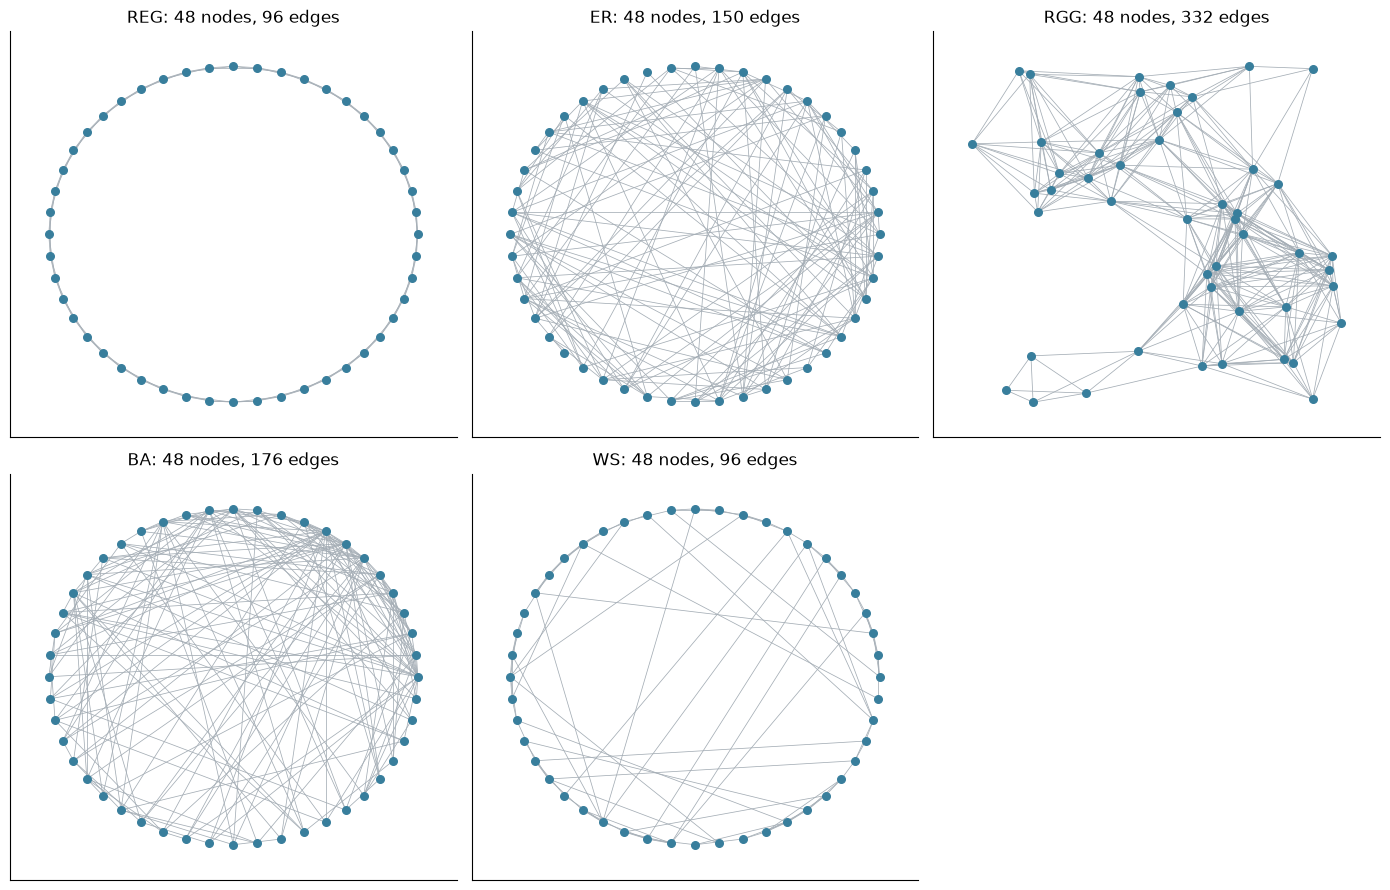

In [3]:
def connected_sample(factory, seed, attempts=1000):
    """Keep connected realizations, with bounded retries and a recorded seed."""
    for attempt in range(attempts):
        graph = factory(seed + attempt)
        if nx.is_connected(graph):
            graph.graph["generation_seed"] = seed + attempt
            graph.graph["attempts"] = attempt + 1
            return graph
    raise RuntimeError("No connected realization found within the retry limit")

def synthetic_graphs(n, seed, random_edges, radius, rewiring):
    factories = {
        "REG": lambda s: nx.watts_strogatz_graph(n, 4, 0, seed=s),
        "ER": lambda s: nx.gnm_random_graph(n, random_edges, seed=s),
        "RGG": lambda s: nx.random_geometric_graph(n, radius, seed=s),
        "BA": lambda s: nx.barabasi_albert_graph(n, 4, seed=s),
        "WS": lambda s: nx.watts_strogatz_graph(n, 4, rewiring, seed=s),
    }
    return {name: connected_sample(factory, seed) for name, factory in factories.items()}

def graph_summary(graph):
    return {"nodes": len(graph), "edges": graph.number_of_edges(),
            "components": nx.number_connected_components(graph),
            "mean_degree": np.mean([degree for _, degree in graph.degree()]),
            "mean_clustering": nx.average_clustering(graph, weight=None),
            "mean_closeness": np.mean(list(nx.closeness_centrality(graph).values()))}

def histogram_grid(values, xlabel, title, bins=15):
    columns = min(3, len(values))
    rows = math.ceil(len(values) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(5*columns, 3.3*rows), squeeze=False)
    for ax, (name, array) in zip(axes.flat, values.items()):
        ax.hist(list(array), bins=bins, color="#387e9c", edgecolor="white")
        ax.set(title=name, xlabel=xlabel, ylabel="Nodes")
    for ax in list(axes.flat)[len(values):]:
        ax.set_visible(False)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

graphs = synthetic_graphs(48, SEED, random_edges=150, radius=.35, rewiring=.25)
summary = pd.DataFrame({name: graph_summary(graph) for name, graph in graphs.items()}).T
summary["generation_seed"] = [graph.graph["generation_seed"] for graph in graphs.values()]
summary["attempts"] = [graph.graph["attempts"] for graph in graphs.values()]
display(summary)
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, (name, graph) in zip(axes.flat, graphs.items()):
    position = nx.get_node_attributes(graph, "pos") if name == "RGG" else nx.circular_layout(graph)
    nx.draw_networkx(graph, position, ax=ax, with_labels=False, node_size=30,
                     node_color="#387e9c", edge_color="#a4adb5", width=.55)
    ax.set_title(f"{name}: {len(graph)} nodes, {graph.number_of_edges()} edges")
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

### What the drawings establish

The lattice distributes connections evenly. Geometry creates local neighborhoods; preferential attachment creates hubs; rewiring introduces long-range shortcuts. A circular drawing does not itself measure locality: its positions are arbitrary except for the geometric graph, whose plotted coordinates generated its edges. The models have different edge counts, so later comparisons are descriptive rather than a controlled test of topology alone.

## Local cohesion: clustering coefficients

For each node, clustering is the fraction of possible edges among its neighbors that actually exist. Values lie between zero and one; NetworkX assigns zero when a node has fewer than two neighbors. We retain the full per-node values, plot their distributions, and compute the mean, population variance, and all tied minima and maxima.

,REG,ER,RGG,BA,WS
node,,,,,
0,0.5,0.2000,0.7750,0.1905,0.3333
1,0.5,0.1778,0.6795,0.1111,0.3333
2,0.5,0.1905,0.8250,0.3056,0.3000
3,0.5,0.2000,0.6593,0.1333,0.3333
4,0.5,0.2000,0.6737,0.2000,0.3333
5,0.5,0.0000,0.8611,0.2000,0.3333
6,0.5,0.1667,0.7053,0.2288,0.3333
7,0.5,0.1389,0.8333,0.1838,0.2000
8,0.5,0.0000,0.8333,0.1474,0.2000


,mean,variance,minimum,minimum_nodes,maximum,maximum_nodes
network,,,,,,
REG,0.5000,0.0000,0.5000,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",0.5000,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
ER,0.1231,0.0053,0.0000,"[5, 8, 14, 18, 22, 30]",0.3333,[12]
RGG,0.7311,0.0129,0.5439,"[9, 20]",1.0000,[42]
BA,0.2287,0.0194,0.0000,"[24, 37, 44]",0.6667,[47]
WS,0.2419,0.0267,0.0000,"[14, 15, 27, 28, 29, 30, 32, 37, 47]",0.6667,"[22, 38]"


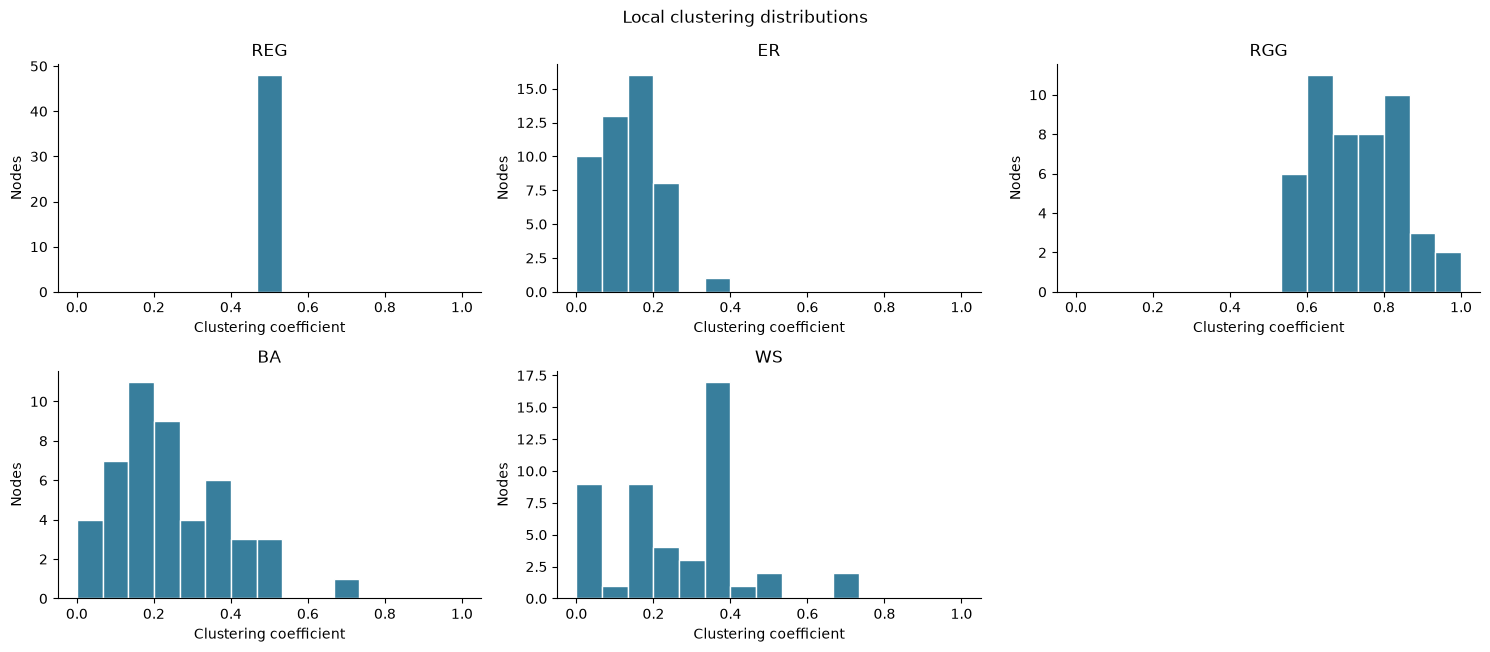

In [4]:
clustering = {name: nx.clustering(graph, weight=None) for name, graph in graphs.items()}
display(pd.DataFrame(clustering).rename_axis("node"))
clustering_rows = []
for name, values in clustering.items():
    array = np.array(list(values.values()))
    clustering_rows.append({"network": name, "mean": array.mean(), "variance": array.var(),
        "minimum": array.min(), "minimum_nodes": [u for u, value in values.items() if np.isclose(value, array.min())],
        "maximum": array.max(), "maximum_nodes": [u for u, value in values.items() if np.isclose(value, array.max())]})
clustering_summary = pd.DataFrame(clustering_rows).set_index("network")
display(clustering_summary)
histogram_grid({name: list(values.values()) for name, values in clustering.items()},
               "Clustering coefficient", "Local clustering distributions", bins=np.linspace(0, 1, 16))

### Interpreting clustering

The lattice has identical local neighborhoods, so its clustering variance is zero. Geometric neighbors tend to be close to each other, creating many triangles. Independent random edges usually create less triangle closure. Rewiring can lower clustering by replacing local edges with shortcuts.

Clustering lies between zero and one and measures local closure. Mean degree, $2m/n$, counts neighbors and describes a separate property. All tied extrema are reported because a shared maximum does not identify one uniquely important node.

## Reachability: path lengths, eccentricity, center, and periphery

Shortest-path lengths count hops. We exclude self-pairs, avoiding the downward bias caused by including a zero for every node. Counting both directions of an undirected pair does not change the mean or variance. Eccentricity is a node's maximum shortest-path distance; the diameter is its maximum over nodes, and the radius its minimum.

We also count, for every node, how many other nodes lie exactly one graph diameter away. This identifies nodes that participate in the largest number of maximally distant pairs, retaining every tie.

In [5]:
path_rows, distance_profiles = [], {}
for name, graph in graphs.items():
    distances = dict(nx.all_pairs_shortest_path_length(graph))
    lengths = np.array([distance for u, targets in distances.items()
                        for v, distance in targets.items() if u != v])
    eccentricity = {u: max(targets.values()) for u, targets in distances.items()}
    diameter, radius = max(eccentricity.values()), min(eccentricity.values())
    at_diameter = {u: sum(distance == diameter for distance in targets.values())
                   for u, targets in distances.items()}
    maximum = max(at_diameter.values())
    distance_profiles[name] = at_diameter
    path_rows.append({"network": name, "mean_path": lengths.mean(), "path_variance": lengths.var(),
        "diameter": diameter, "radius": radius,
        "center": [u for u, value in eccentricity.items() if value == radius],
        "periphery": [u for u, value in eccentricity.items() if value == diameter],
        "most_diameter_partners": maximum,
        "nodes_with_most_partners": [u for u, value in at_diameter.items() if value == maximum]})
    assert np.isclose(lengths.mean(), nx.average_shortest_path_length(graph))
path_summary = pd.DataFrame(path_rows).set_index("network")
display(path_summary)
display(pd.DataFrame(distance_profiles).rename_axis("node").rename(columns=lambda s: s+" diameter partners"))

,mean_path,path_variance,diameter,radius,center,periphery,most_diameter_partners,nodes_with_most_partners
network,,,,,,,,
REG,6.3830,11.5129,12,12,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",3,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
ER,2.2686,0.5067,4,3,"[0, 1, 2, 7, 8, 9, 15, 16, 17, 19, 21, 23, 24,...","[3, 4, 5, 6, 10, 11, 12, 13, 14, 18, 20, 22, 2...",15,[30]
RGG,2.2473,1.1596,6,3,"[6, 15, 25, 40, 46]","[1, 5, 19, 42, 45]",4,[42]
BA,2.0585,0.3689,4,2,"[0, 6, 7, 15]","[25, 37]",1,"[25, 37]"
WS,3.2128,1.3874,6,4,"[31, 32, 34]","[0, 1, 2, 11, 13, 19, 21, 27, 38, 39, 41, 43, ...",7,[0]


,REG diameter partners,ER diameter partners,RGG diameter partners,BA diameter partners,WS diameter partners
node,,,,,
0,3,0,0,0,7
1,3,0,1,0,2
2,3,0,0,0,1
3,3,1,0,0,0
4,3,2,0,0,0
5,3,1,1,0,0
6,3,2,0,0,0
7,3,0,0,0,0
8,3,0,0,0,0


### Interpreting distances

The regular ring requires many local steps to reach distant nodes. Hubs and shortcuts can reduce those distances. The center minimizes worst-case travel distance; the periphery maximizes it. These are topological roles and need not coincide with high-degree nodes or the visual center of an arbitrary layout. The table separates typical distance, distance variability, and worst-case distance because each answers a different reachability question.

## Node roles: degree and centrality

Degree counts direct neighbors; normalized degree centrality divides by $n-1$. Closeness favors short distances to all others. Betweenness measures the fraction of shortest paths passing through a node. Katz counts walks of every length, attenuating longer walks.

For Katz we use $\alpha=0.9/\rho(A)$, where $\rho(A)$ is the adjacency spectral radius, ensuring convergence. It is set per graph, so raw Katz scores are not on one common attenuation scale. Empirical CDFs use ranks $1/n,\ldots,1$ and therefore reach one at the largest value.

,,mean,variance,maximum,top_nodes
measure,network,,,,
Degree,REG,4.0000,0.0000e+00,4.0000,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
Degree centrality,REG,0.0851,0.0000e+00,0.0851,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
Closeness,REG,0.1567,7.7037e-34,0.1567,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
Betweenness,REG,0.1170,3.6111e-35,0.1170,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
Katz,REG,0.1443,0.0000e+00,0.1443,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
Degree,ER,6.2500,4.2708e+00,10.0000,"[1, 46]"
Degree centrality,ER,0.1330,1.9334e-03,0.2128,"[1, 46]"
Closeness,ER,0.4441,1.3280e-03,0.5054,[7]
Betweenness,ER,0.0276,3.3614e-04,0.0869,[28]


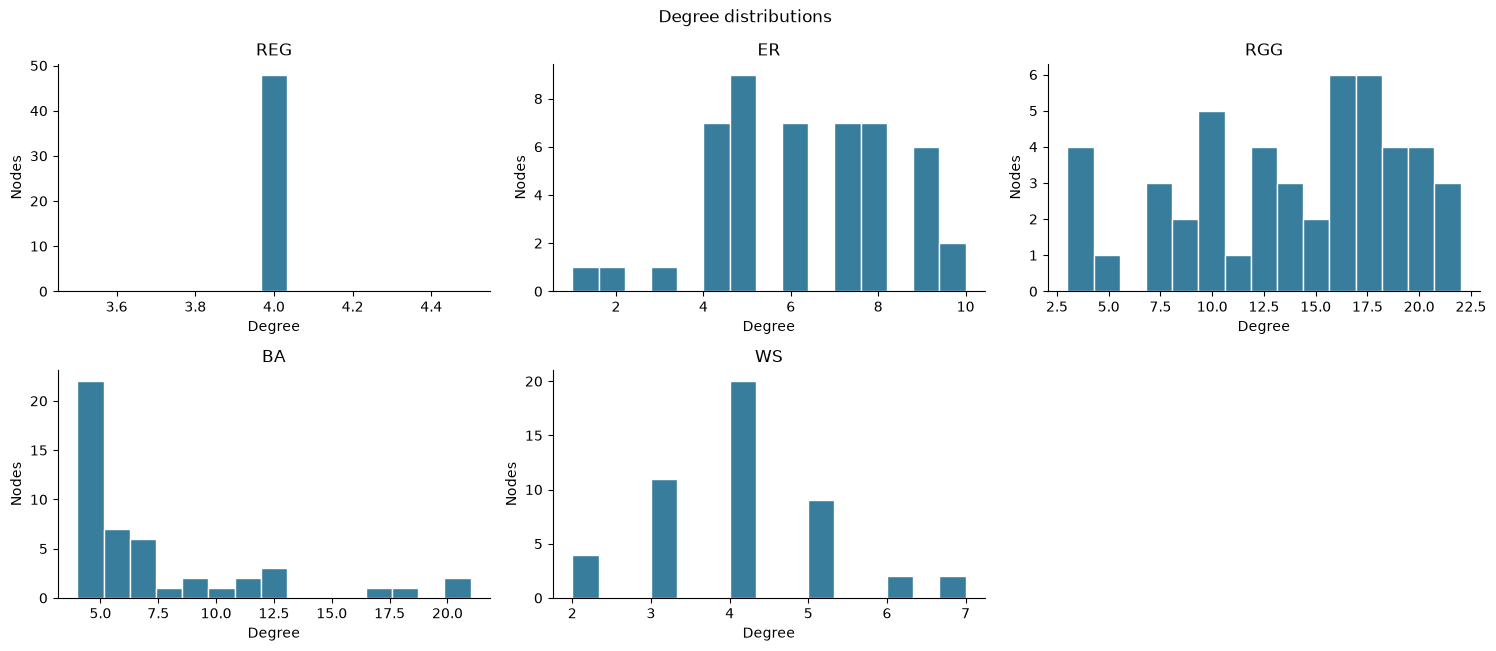

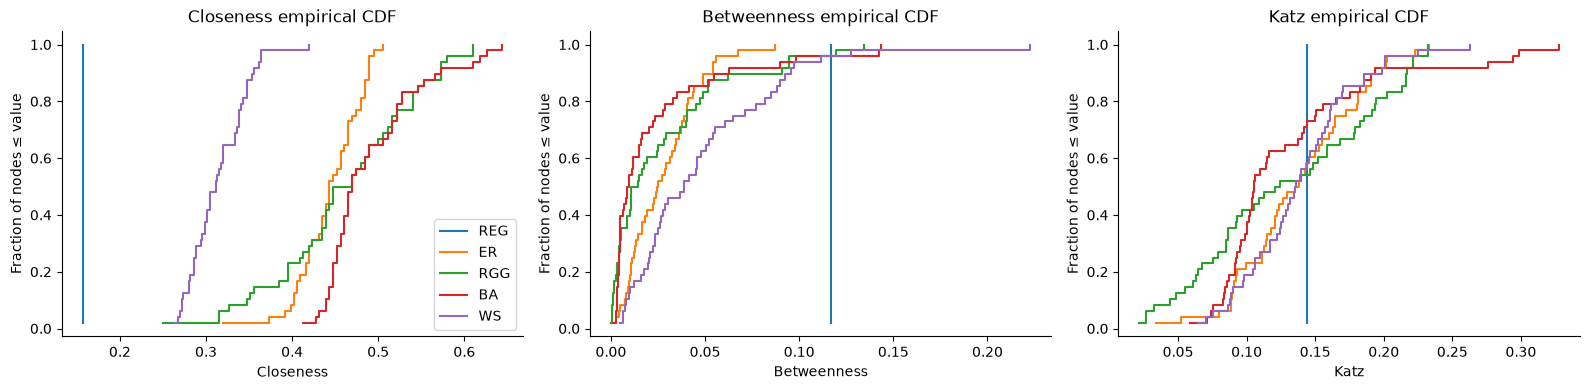

In [6]:
centralities = {}
for name, graph in graphs.items():
    spectral_radius = float(np.linalg.eigvalsh(nx.to_numpy_array(graph, weight=None)).max())
    centralities[name] = {
        "Degree": dict(graph.degree()),
        "Degree centrality": nx.degree_centrality(graph),
        "Closeness": nx.closeness_centrality(graph),
        "Betweenness": nx.betweenness_centrality(graph),
        "Katz": nx.katz_centrality(graph, alpha=.9/spectral_radius, max_iter=3000, tol=1e-10, weight=None),
    }
rows = []
for name, measures in centralities.items():
    for measure, values in measures.items():
        array = np.array(list(values.values()))
        rows.append({"network": name, "measure": measure, "mean": array.mean(),
                     "variance": array.var(), "maximum": array.max(),
                     "top_nodes": [u for u, value in values.items() if np.isclose(value, array.max())]})
centrality_summary = pd.DataFrame(rows).set_index(["measure", "network"])
display(centrality_summary)
histogram_grid({name: list(values["Degree"].values()) for name, values in centralities.items()},
               "Degree", "Degree distributions")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, measure in zip(axes, ["Closeness", "Betweenness", "Katz"]):
    for name, values in centralities.items():
        array = np.sort(list(values[measure].values()))
        ax.step(array, np.arange(1, len(array)+1)/len(array), where="post", label=name)
    ax.set(xlabel=measure, ylabel="Fraction of nodes ≤ value", title=measure+" empirical CDF")
axes[0].legend()
plt.tight_layout()
plt.show()

### Interpreting centrality

A steep CDF means many nodes have similar scores; a long right tail indicates a few unusually central nodes. High degree captures direct reach, while high betweenness captures brokerage. They need not agree. The lattice's symmetry creates ties that should be reported rather than broken arbitrarily. On heterogeneous networks, compare the named top nodes across measures to distinguish hubs from bridges.

## PageRank on the Stanford web graph

The [SNAP Stanford web graph](https://snap.stanford.edu/data/web-Stanford.html) contains directed hyperlinks collected in 2002. We preserve edge directions, rank weakly connected components by size, and analyze the **40th largest component** using index 39. A deterministic secondary ordering resolves equal-size components.

PageRank with damping 0.85 is the stationary probability of a random surfer who follows outgoing links or teleports. Scores are computed on the selected induced subgraph, so they describe that component rather than the entire web graph.

Full graph: 281,903 pages, 2,312,497 directed links
Component rank 40: 250 pages, 498 links


,PageRank
97904,0.0046
10506,0.0046
93249,0.0044
233883,0.0044
122161,0.0042
157065,0.0042
208665,0.0041
276606,0.0041
152168,0.0041
57252,0.0041


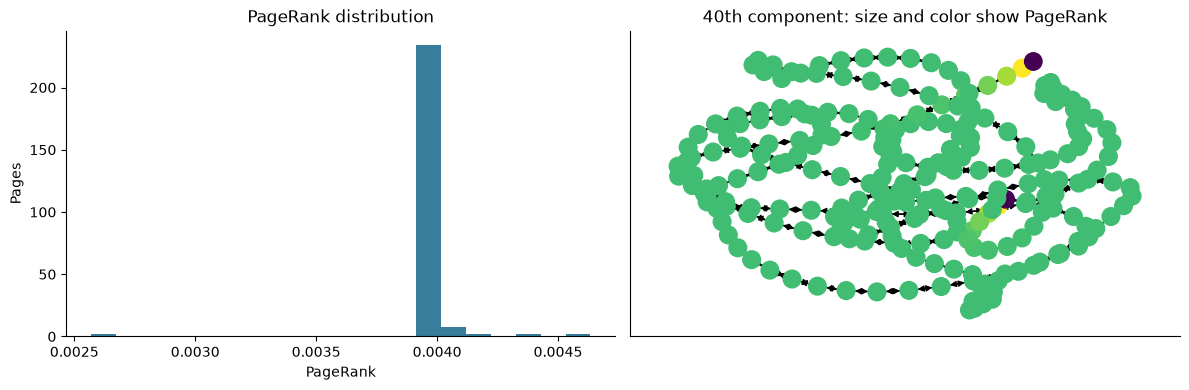

In [7]:
COMPONENT_RANK = 40
web_path = fetch_data("web-Stanford.txt.gz")
with gzip.open(web_path, "rt") as file:
    web = nx.read_edgelist(file, create_using=nx.DiGraph, nodetype=int, data=False, comments="#")
components = sorted(nx.weakly_connected_components(web), key=lambda group: (-len(group), min(group)))
if len(components) < COMPONENT_RANK:
    raise ValueError("The graph has fewer than 40 weakly connected components")
web_component = web.subgraph(components[COMPONENT_RANK-1]).copy()
print(f"Full graph: {len(web):,} pages, {web.number_of_edges():,} directed links")
print(f"Component rank {COMPONENT_RANK}: {len(web_component)} pages, {web_component.number_of_edges()} links")
del web, components
pagerank = nx.pagerank(web_component, alpha=.85, max_iter=1000, tol=1e-12, weight=None)
assert np.isclose(sum(pagerank.values()), 1)
display(pd.Series(pagerank, name="PageRank").sort_values(ascending=False).head(10).to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(list(pagerank.values()), bins=min(20, len(web_component)), color="#387e9c")
axes[0].set(xlabel="PageRank", ylabel="Pages", title="PageRank distribution")
position = nx.spring_layout(web_component, seed=SEED)
nx.draw_networkx(web_component, position, ax=axes[1], with_labels=len(web_component)<40,
                 node_size=[150+3000*pagerank[u] for u in web_component],
                 node_color=[pagerank[u] for u in web_component], cmap="viridis", font_size=7,
                 arrows=True, arrowsize=9)
axes[1].set_title("40th component: size and color show PageRank")
plt.tight_layout()
plt.show()

### Reading the PageRank result

A small number of high scores means the random surfer spends disproportionate time on a few pages. Incoming links from already prominent pages can matter more than a large raw incoming-link count. Teleportation and dangling-node handling keep the probability distribution defined even if this weakly connected component is not strongly connected. The histogram shows concentration; the ranking identifies the pages receiving that mass.

## Connectivity across network parameters

We generate **100 independent realizations per parameter setting** for 100 and 200 nodes. Each plot reports the fraction that are connected; samples are never regenerated to enforce connectivity here. The sweeps cover six model families:

| Model | Parameter grid |
|---|---|
| REG | ring degree 2, 4, 6, 8, 10 |
| ER | 100 through 800 edges, step 100 |
| Gilbert | edge probability 0.01 through 0.10, step 0.01 |
| RGG | radius 0.025 through 0.25, step 0.025 |
| BA | attachment parameter 2, 4, 6, 8, 10 |
| WS | ring degree 2 through 10 and rewiring 0.1 through 0.7 |

This section can take several minutes. Reproducible, distinct seeds are used for every realization. Finite samples estimate a transition region; they cannot establish an exact asymptotic critical point.

Connectivity sweeps: 100%|##########| 2/2 [00:18<00:00,  9.29s/it]


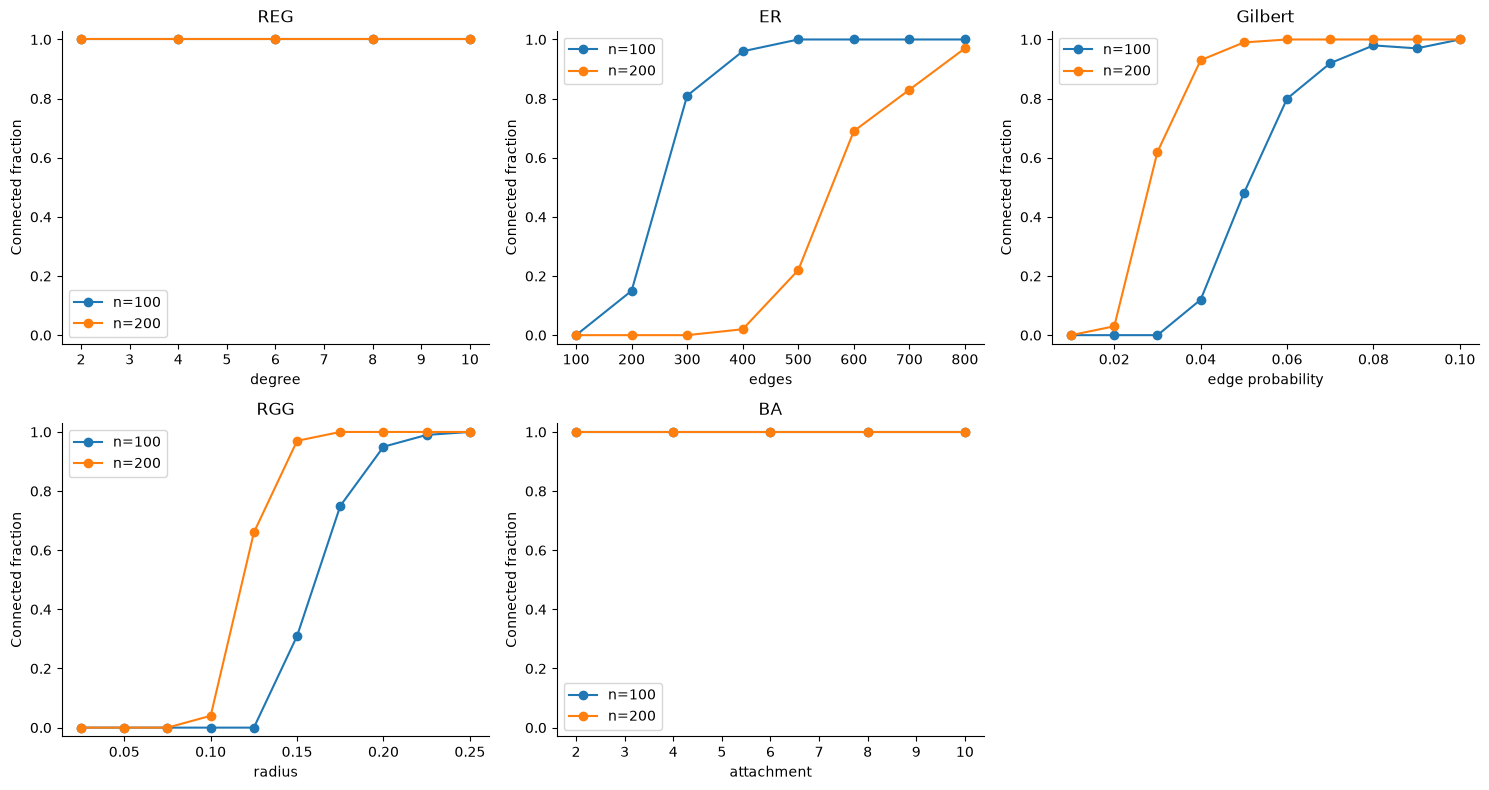

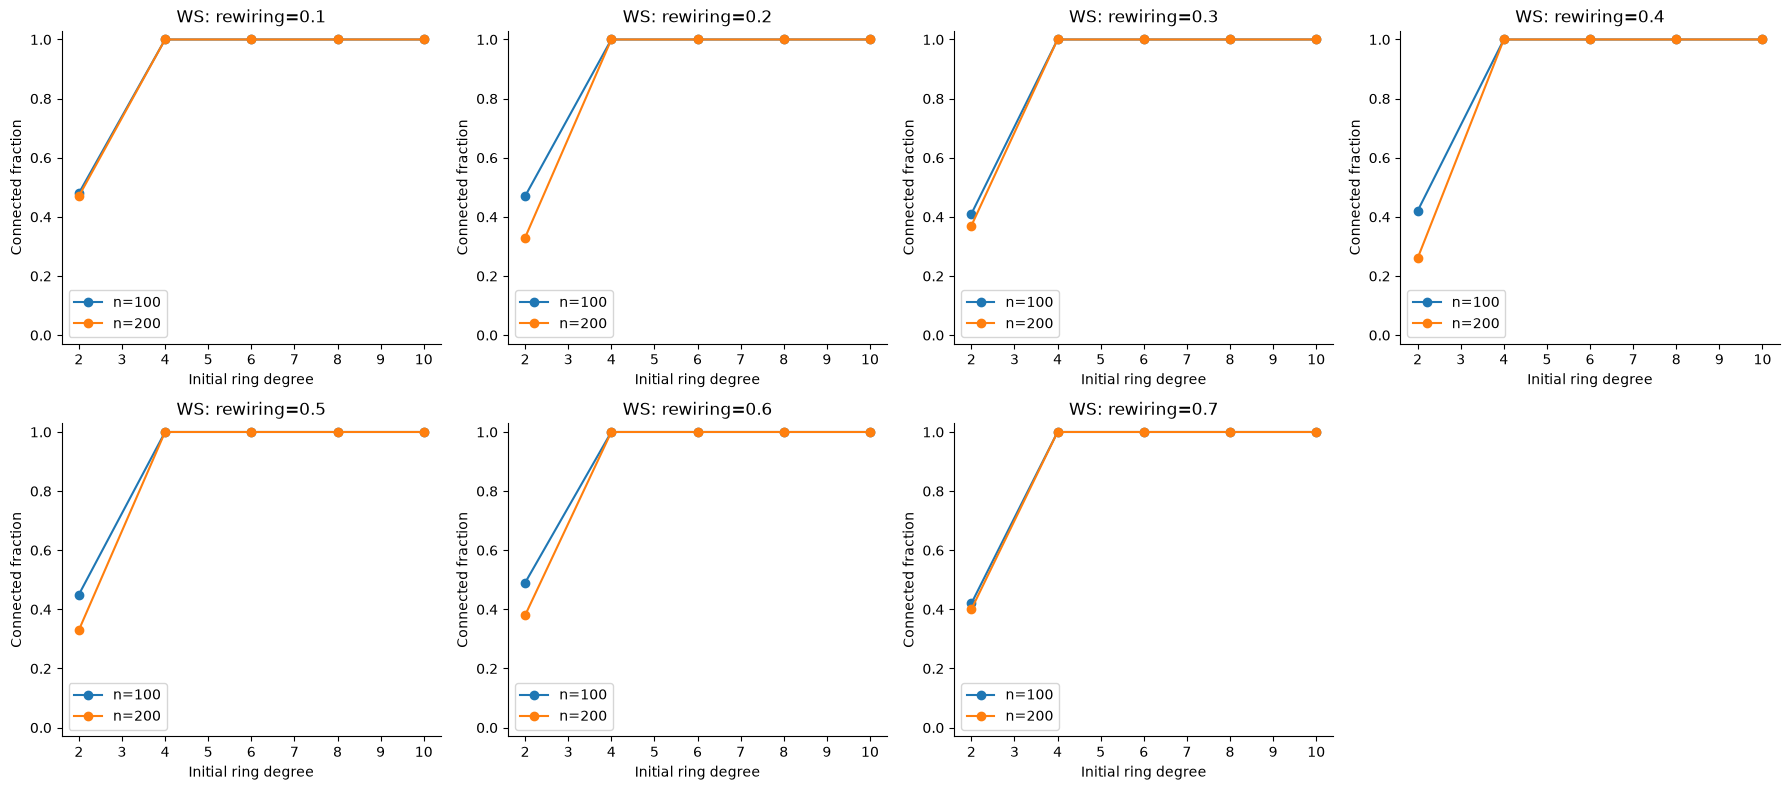

,model,nodes,rewiring,first_grid_value_at_least_50_percent
0,BA,100,NaN,2.000
1,BA,200,NaN,2.000
2,ER,100,NaN,300.000
3,ER,200,NaN,600.000
4,Gilbert,100,NaN,0.060
5,Gilbert,200,NaN,0.030
6,REG,100,NaN,2.000
7,REG,200,NaN,2.000
8,RGG,100,NaN,0.175
9,RGG,200,NaN,0.125


In [8]:
REPEATS = 100
seed_generator = random.Random(SEED)
connectivity_rows = []
def record_connectivity(model, n, parameter, value, factory, rewiring=None):
    connected_count = 0
    for _ in range(REPEATS):
        graph = factory(seed_generator.randrange(2**32))
        connected_count += nx.is_connected(graph)
    connectivity_rows.append({"model": model, "nodes": n, "parameter": parameter,
        "value": value, "rewiring": rewiring, "connected_fraction": connected_count/REPEATS})

for n_nodes in tqdm([100, 200], desc="Connectivity sweeps"):
    for degree in range(2, 11, 2):
        record_connectivity("REG", n_nodes, "degree", degree,
            lambda s: nx.watts_strogatz_graph(n_nodes, degree, 0, seed=s))
        record_connectivity("BA", n_nodes, "attachment", degree,
            lambda s: nx.barabasi_albert_graph(n_nodes, degree, seed=s))
    for edges in range(100, 801, 100):
        record_connectivity("ER", n_nodes, "edges", edges,
            lambda s: nx.gnm_random_graph(n_nodes, edges, seed=s))
    for probability in np.arange(1, 11)/100:
        record_connectivity("Gilbert", n_nodes, "edge probability", probability,
            lambda s: nx.gnp_random_graph(n_nodes, probability, seed=s))
    for radius in np.arange(1, 11)*.025:
        record_connectivity("RGG", n_nodes, "radius", radius,
            lambda s: nx.random_geometric_graph(n_nodes, radius, seed=s))
    for rewiring in np.arange(1, 8)/10:
        for degree in range(2, 11, 2):
            record_connectivity("WS", n_nodes, "degree", degree,
                lambda s: nx.watts_strogatz_graph(n_nodes, degree, rewiring, seed=s), rewiring)
connectivity = pd.DataFrame(connectivity_rows)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, model in zip(axes.flat, ["REG", "ER", "Gilbert", "RGG", "BA"]):
    for n_nodes, group in connectivity[connectivity.model.eq(model)].groupby("nodes"):
        ax.plot(group.value, group.connected_fraction, marker="o", label=f"n={n_nodes}")
    ax.set(title=model, xlabel=group.parameter.iloc[0], ylabel="Connected fraction", ylim=(-.03, 1.03))
    ax.legend()
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (rewiring, subset) in zip(axes.flat, connectivity[connectivity.model.eq("WS")].groupby("rewiring")):
    for n_nodes, group in subset.groupby("nodes"):
        ax.plot(group.value, group.connected_fraction, marker="o", label=f"n={n_nodes}")
    ax.set(title=f"WS: rewiring={rewiring:.1f}", xlabel="Initial ring degree", ylabel="Connected fraction", ylim=(-.03, 1.03))
    ax.legend()
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()
transition_rows = []
for (model, n_nodes, rewiring), group in connectivity.groupby(["model", "nodes", "rewiring"], dropna=False):
    reached = group[group.connected_fraction.ge(.5)].sort_values("value")
    transition_rows.append({"model": model, "nodes": n_nodes, "rewiring": rewiring,
        "first_grid_value_at_least_50_percent": reached.value.iloc[0] if len(reached) else np.nan})
display(pd.DataFrame(transition_rows))

### Interpreting connectivity transitions

REG rings and BA networks with positive attachment are connected by construction: their flat curves do **not** indicate a measured threshold. ER and Gilbert graphs become connected as isolated vertices and small components disappear; the classical large-$n$ reference is mean degree near $\log n$, not a universal fixed edge count. RGG connectivity depends on spatial gaps and boundary effects. WS rewiring can break connectivity at low degree, so connectivity is not guaranteed merely because its starting ring is connected.

The table identifies the first sampled value reaching 50% connectivity, not an exact critical parameter. A steep change between sampled points suggests a narrow transition on this grid. With 100 trials, an estimated probability near 0.5 has standard error about 0.05; observed fractions of zero or one still do not prove population probabilities of exactly zero or one.

## Robustness to targeted node removal

A minimum node cut is the smallest set of vertices whose removal disconnects a connected graph. We compute both the cut size and the vertices it contains for the 48-node reference graphs. This is a worst-case structural vulnerability, distinct from average resilience to random failures.

In [9]:
cut_rows = []
for name, graph in graphs.items():
    cut = nx.minimum_node_cut(graph)
    damaged = graph.copy()
    damaged.remove_nodes_from(cut)
    cut_rows.append({"network": name, "minimum_cut_size": len(cut), "cut_nodes": sorted(cut),
                     "components_after_removal": nx.number_connected_components(damaged)})
display(pd.DataFrame(cut_rows).set_index("network"))

,minimum_cut_size,cut_nodes,components_after_removal
network,,,
REG,4,"[0, 44, 45, 47]",2
ER,1,[28],2
RGG,2,"[14, 28]",2
BA,4,"[0, 4, 12, 21]",2
WS,2,"[1, 17]",2


## From a ring lattice to a small-world network

For 308 nodes and initial degree four, sweep rewiring probability from zero to one in steps of 0.1. At each value we measure mean clustering and the standard mean shortest-path length. Connected sampling makes all path means comparable, and generation attempts are shown.

WS at rewiring one is highly randomized but is **not exactly an Erdős–Rényi graph**: its construction constrains the edge count and degree structure differently.

,clustering,mean_path,generation_attempts
rewiring,,,
0.0,0.5000,38.8762,1
0.1,0.3606,6.4759,1
0.2,0.2670,5.5772,1
0.3,0.2021,5.0381,1
0.4,0.1436,4.8509,1
0.5,0.0737,4.5447,1
0.6,0.0459,4.4257,1
0.7,0.0182,4.4123,1
0.8,0.0146,4.3970,1


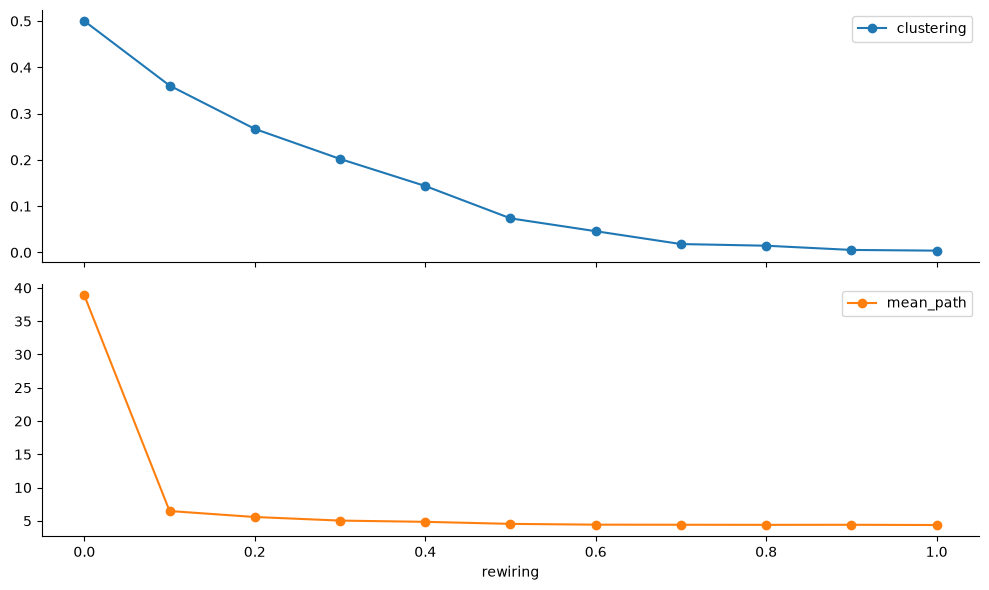

At zero rewiring the mean path is **38.88** hops with clustering **0.500**. At rewiring 0.1 these become **6.48** and **0.361**. The paired changes show how a small proportion of shortcuts changes global reachability while some local cohesion survives.

In [10]:
rewiring_rows = []
for probability in np.arange(11)/10:
    graph = connected_sample(lambda s: nx.watts_strogatz_graph(308, 4, probability, seed=s), SEED)
    rewiring_rows.append({"rewiring": probability, "clustering": nx.average_clustering(graph),
                         "mean_path": nx.average_shortest_path_length(graph),
                         "generation_attempts": graph.graph["attempts"]})
rewiring_results = pd.DataFrame(rewiring_rows).set_index("rewiring")
display(rewiring_results)
rewiring_results[["clustering", "mean_path"]].plot(subplots=True, marker="o", figsize=(10, 6))
plt.tight_layout()
plt.show()
display(Markdown(f"At zero rewiring the mean path is **{rewiring_results.loc[0, 'mean_path']:.2f}** hops "
                 f"with clustering **{rewiring_results.loc[0, 'clustering']:.3f}**. "
                 f"At rewiring 0.1 these become **{rewiring_results.loc[.1, 'mean_path']:.2f}** "
                 f"and **{rewiring_results.loc[.1, 'clustering']:.3f}**. "
                 "The paired changes show how a small proportion of shortcuts changes global reachability while some local cohesion survives."))

## A real network: Game of Thrones, season one

The [Beveridge character-interaction dataset](https://github.com/mathbeveridge/gameofthrones) connects characters who interact or co-occur according to the documented script-based rules. We use **season one**. Interaction counts are retained as edge attributes; the measures below describe unweighted topology.

We visualize the network, inspect degree and clustering distributions, compute path length on its largest connected component if necessary, and rank the top five characters separately by degree, closeness, and betweenness.

,Game of Thrones S1
nodes,126.0000
edges,549.0000
components,1.0000
mean_degree,8.7143
mean_clustering,0.6297
mean_closeness,0.3893
path_component_nodes,126.0000
mean_path_in_largest_component,2.6447


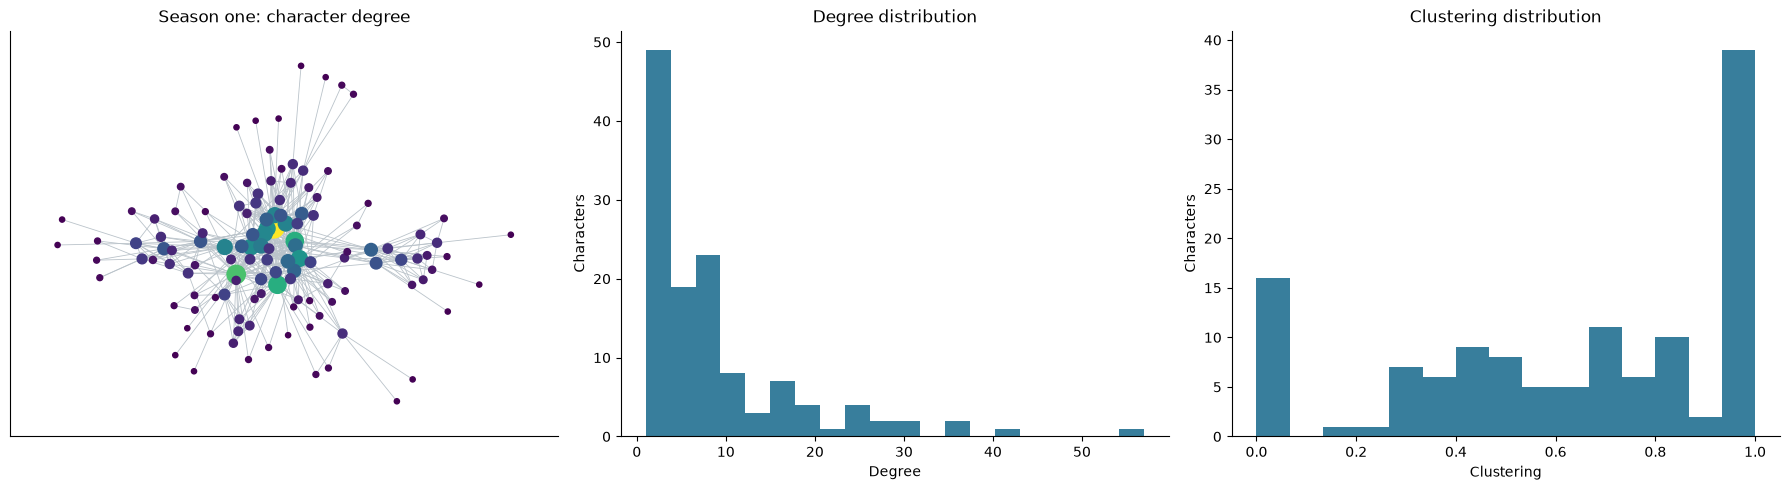

character    score
measure     rank                   
Degree      1          NED  57.0000
            2       TYRION  41.0000
            3      CATELYN  36.0000
            4       ROBERT  36.0000
            5         ROBB  30.0000
Closeness   1          NED   0.6281
            2       ROBERT   0.5531
            3      CATELYN   0.5507
            4       TYRION   0.5435
            5          JON   0.5187
Betweenness 1          NED   0.3033
            2       TYRION   0.1630
            3      CATELYN   0.1183
            4       ROBERT   0.1104
            5     DAENERYS   0.1014

,mean_degree,mean_clustering,mean_closeness
REG,4.0000,0.5000,0.1567
ER,6.2500,0.1231,0.4441
RGG,13.8333,0.7311,0.4613
BA,7.3333,0.2287,0.4913
WS,4.0000,0.2419,0.3145
GoT S1,8.7143,0.6297,0.3893


In [11]:
got = load_got(1)
got_connected = got.subgraph(max(nx.connected_components(got), key=len)).copy()
got_stats = graph_summary(got)
got_stats["path_component_nodes"] = len(got_connected)
got_stats["mean_path_in_largest_component"] = nx.average_shortest_path_length(got_connected)
display(pd.Series(got_stats, name="Game of Thrones S1").to_frame())
position = nx.spring_layout(got, seed=SEED, weight=None)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
nx.draw_networkx(got, position, ax=axes[0], with_labels=False,
                 node_size=[10+4*got.degree(u) for u in got],
                 node_color=[got.degree(u) for u in got], cmap="viridis", edge_color="#bac3ca", width=.6)
axes[0].set_title("Season one: character degree")
axes[1].hist([degree for _, degree in got.degree()], bins=20, color="#387e9c")
axes[1].set(xlabel="Degree", ylabel="Characters", title="Degree distribution")
axes[2].hist(list(nx.clustering(got).values()), bins=np.linspace(0, 1, 16), color="#387e9c")
axes[2].set(xlabel="Clustering", ylabel="Characters", title="Clustering distribution")
plt.tight_layout()
plt.show()
got_centralities = {"Degree": dict(got.degree()), "Closeness": nx.closeness_centrality(got),
                    "Betweenness": nx.betweenness_centrality(got, weight=None)}
leaders = []
for measure, values in got_centralities.items():
    for rank, (character, value) in enumerate(sorted(values.items(), key=lambda pair: (-pair[1], pair[0]))[:5], 1):
        leaders.append({"measure": measure, "rank": rank, "character": character, "score": value})
display(pd.DataFrame(leaders).set_index(["measure", "rank"]))
comparison = summary[["mean_degree", "mean_clustering", "mean_closeness"]].copy()
comparison.loc["GoT S1"] = [got_stats[column] for column in comparison.columns]
display(comparison)

### What this real-network comparison supports

A skewed degree distribution is consistent with a few central characters interacting with many others. High clustering reflects overlapping narrative groups. Degree leaders are widely connected characters; betweenness leaders connect otherwise separated parts of the story; closeness leaders have short routes across it.

In this snapshot, Ned leads all three rankings; Daenerys appears among the betweenness leaders despite not appearing in the top-five degree ranking, illustrating brokerage beyond direct popularity. The skewed degree pattern resembles the BA reference, while the much higher clustering indicates additional local cohesion.

These are qualitative similarities to the reference models, not evidence that one model generated the network. In particular, a heavy-looking tail in a small graph does not establish a power law or prove that the graph is scale-free. Different sizes and densities also affect the summary statistics.

## Conclusions

Network structure has several independent dimensions: local cohesion, path efficiency, node roles, and vulnerability to removal. The rewiring experiment makes the local–global trade-off explicit. Connectivity sweeps show which parameter regimes support an intact network, while PageRank and the character rankings demonstrate why the appropriate notion of importance depends on the application.

**Data sources:** [Stanford web graph](https://snap.stanford.edu/data/web-Stanford.html); [Game of Thrones interaction networks](https://github.com/mathbeveridge/gameofthrones), Andrew Beveridge and Michael Chemers. The latter data are distributed under CC BY-NC-SA 4.0; retain attribution when reusing them.